In [295]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("libraries imported")

libraries imported


In [296]:
df=pd.read_csv("D:/cafe sales main.csv")
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2,4,Credit Card,Takeaway,08-09-2023
1,TXN_4977031,Cake,4,3,12,Cash,In-store,16-05-2023
2,TXN_4271903,Cookie,4,1,ERROR,Credit Card,In-store,19-07-2023
3,TXN_7034554,Salad,2,5,10,UNKNOWN,UNKNOWN,27-04-2023
4,TXN_3160411,Coffee,2,2,4,Digital Wallet,In-store,11-06-2023


In [297]:
#understand the data
print("rows and columns:", df.shape)
print("column names:",list(df.columns))

rows and columns: (10000, 8)
column names: ['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date']


In [298]:
#data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


In [299]:
# Check Missing Values
print("Checking missing values")

print(df.isnull().sum())

Checking missing values
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64


In [300]:
# Replace UNKNOWN and ERROR
df = df.replace(["UNKNOWN", "ERROR"], np.nan)

print("Invalid values replaced")

Invalid values replaced


In [301]:
# handle missing values
print("Missing values before cleaning")

print(df.isnull().sum())

df["Item"] = df["Item"].fillna("Unknown")

df["Payment Method"] = df["Payment Method"].fillna("Unknown")

df["Location"] = df["Location"].fillna("Unknown")

Missing values before cleaning
Transaction ID         0
Item                 969
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64


In [302]:
# convert numeric values
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

df["Price Per Unit"] = pd.to_numeric(df["Price Per Unit"], errors="coerce")

df["Total Spent"] = pd.to_numeric(df["Total Spent"], errors="coerce")

In [303]:
# fill missing numeric values
df["Quantity"] = df["Quantity"].fillna(
    round(df["Quantity"].median())
)

df["Price Per Unit"] = df["Price Per Unit"].fillna(
    df["Price Per Unit"].median()
)

print("Numeric missing values handled")

Numeric missing values handled


In [304]:
# remove duplicate rows
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))

Duplicate rows: 0
Rows after removing duplicates: 10000


In [305]:
# convert date column
df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("First date:", df["Transaction Date"].min())

print("Last date:", df["Transaction Date"].max())

First date: 2023-01-01 00:00:00
Last date: 2023-12-31 00:00:00


In [306]:
# create new columns
df["Month"] = df["Transaction Date"].dt.month_name()

df["Day Name"] = df["Transaction Date"].dt.day_name()

df[["Transaction Date", "Month", "Day Name"]].head()

,Transaction Date,Month,Day Name
0,2023-09-08,September,Friday
1,2023-05-16,May,Tuesday
2,2023-07-19,July,Wednesday
3,2023-04-27,April,Thursday
4,2023-06-11,June,Sunday


In [307]:
# create total spent column
df["Total Spent"] = df["Quantity"] * df["Price Per Unit"]

print("Total Sales:", df["Total Spent"].sum())

df.head()

Total Sales: 89481.5


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Month,Day Name
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,September,Friday
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,May,Tuesday
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,July,Wednesday
3,TXN_7034554,Salad,2.0,5.0,10.0,Unknown,Unknown,2023-04-27,April,Thursday
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,June,Sunday


In [308]:
# save cleaned dataset
df.to_csv("cleaned_cafe_sales.csv", index=False)

print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully


In [ ]:
# exploratory data analysis


print("EXPLORATORY DATA ANALYSIS")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nLast 5 Rows:")
print(df.tail())

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

EXPLORATORY DATA ANALYSIS

Dataset Shape:
(10000, 10)

First 5 Rows:
  Transaction ID    Item  Quantity  Price Per Unit  Total Spent  \
0    TXN_1961373  Coffee       2.0             2.0          4.0   
1    TXN_4977031    Cake       4.0             3.0         12.0   
2    TXN_4271903  Cookie       4.0             1.0          4.0   
3    TXN_7034554   Salad       2.0             5.0         10.0   
4    TXN_3160411  Coffee       2.0             2.0          4.0   

   Payment Method  Location Transaction Date      Month   Day Name  
0     Credit Card  Takeaway       2023-09-08  September     Friday  
1            Cash  In-store       2023-05-16        May    Tuesday  
2     Credit Card  In-store       2023-07-19       July  Wednesday  
3         Unknown   Unknown       2023-04-27      April   Thursday  
4  Digital Wallet  In-store       2023-06-11       June     Sunday  

Last 5 Rows:
     Transaction ID      Item  Quantity  Price Per Unit  Total Spent  \
9995    TXN_7672686    Coffe

In [310]:
# descriptive statistical analysis
print("Statistical Analysis")

print(df.describe())


Statistical Analysis
           Quantity  Price Per Unit   Total Spent            Transaction Date
count  10000.000000     10000.00000  10000.000000                        9540
mean       3.027100         2.95265      8.948150  2023-07-01 23:00:31.698113
min        1.000000         1.00000      1.000000         2023-01-01 00:00:00
25%        2.000000         2.00000      4.000000         2023-04-01 00:00:00
50%        3.000000         3.00000      8.000000         2023-07-02 00:00:00
75%        4.000000         4.00000     12.000000         2023-10-02 00:00:00
max        5.000000         5.00000     25.000000         2023-12-31 00:00:00
std        1.384614         1.24396      5.831191                         NaN


In [311]:
# categorical analysis
print("Item Count:")
print(df["Item"].value_counts())

print("\nPayment Method Count:")
print(df["Payment Method"].value_counts())

print("\nLocation Count:")
print(df["Location"].value_counts())

Item Count:
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
Unknown      969
Name: count, dtype: int64

Payment Method Count:
Payment Method
Unknown           3178
Digital Wallet    2291
Credit Card       2273
Cash              2258
Name: count, dtype: int64

Location Count:
Location
Unknown     3961
Takeaway    3022
In-store    3017
Name: count, dtype: int64


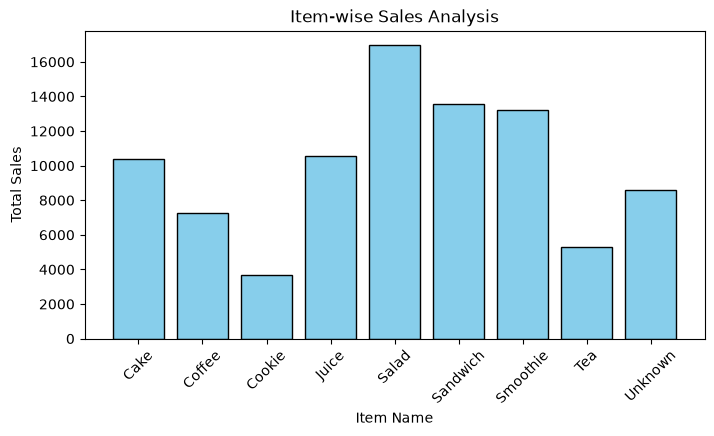

In [312]:
# Item-wise Sales – Bar Chart
plt.figure(figsize=(8,4))

sales = df.groupby("Item")["Total Spent"].sum()

plt.bar(sales.index, sales.values, color="skyblue", edgecolor="black")

plt.title("Item-wise Sales Analysis")
plt.xlabel("Item Name")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

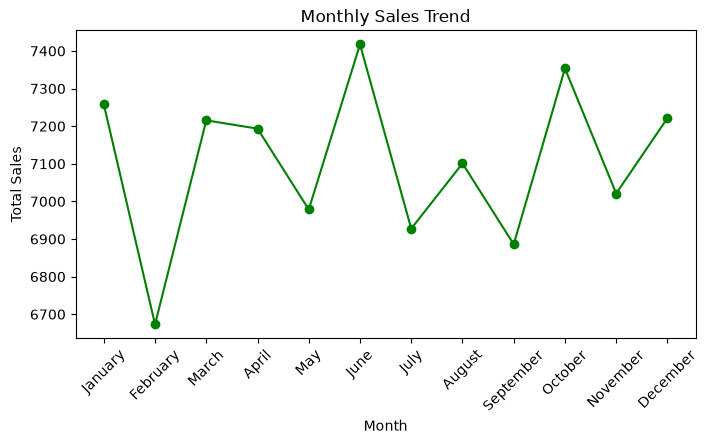

In [313]:
# Monthly Sales – Line Chart
plt.figure(figsize=(8,4))

months = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]

sales = df.groupby("Month")["Total Spent"].sum().reindex(months)

plt.plot(sales.index, sales.values, color="green", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

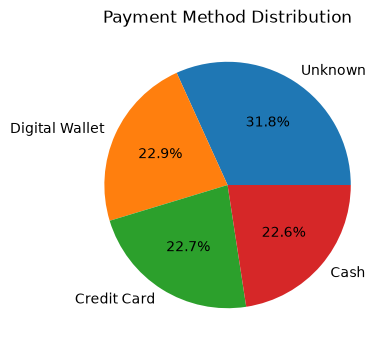

In [314]:
# Payment Method – Pie Chart
plt.figure(figsize=(8,4))

payment = df["Payment Method"].value_counts()

plt.pie(payment, labels=payment.index, autopct="%1.1f%%")

plt.title("Payment Method Distribution")
plt.show()

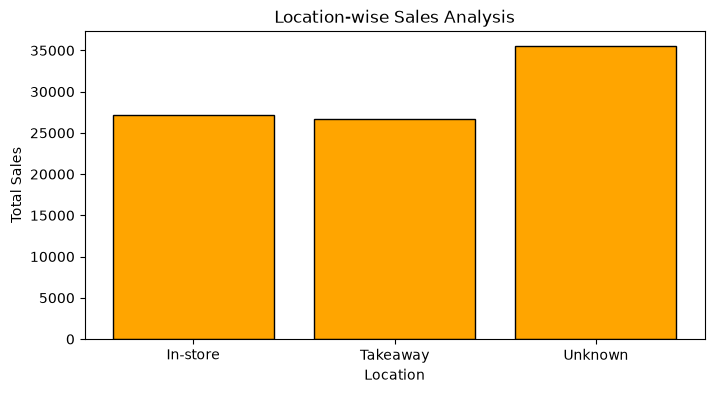

In [315]:
# Location-wise Sales – Bar Chart
plt.figure(figsize=(8,4))

sales = df.groupby("Location")["Total Spent"].sum()

plt.bar(sales.index, sales.values, color="orange", edgecolor="black")

plt.title("Location-wise Sales Analysis")
plt.xlabel("Location")
plt.ylabel("Total Sales")
plt.show()

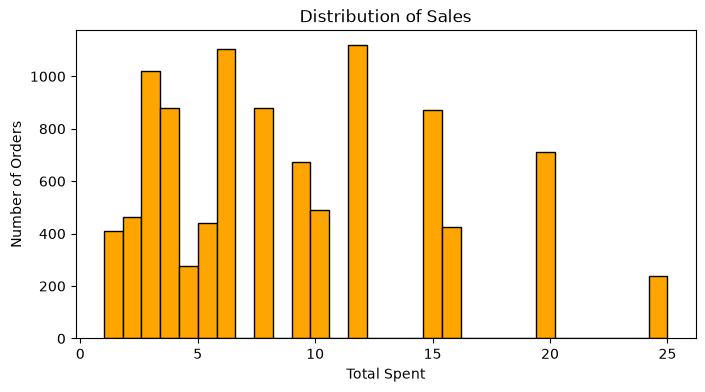

In [316]:
# Sales Distribution – Histogram
plt.figure(figsize=(8,4))

plt.hist(df["Total Spent"].dropna(), bins=30,
         color="orange", edgecolor="black")

plt.title("Distribution of Sales")
plt.xlabel("Total Spent")
plt.ylabel("Number of Orders")
plt.show()

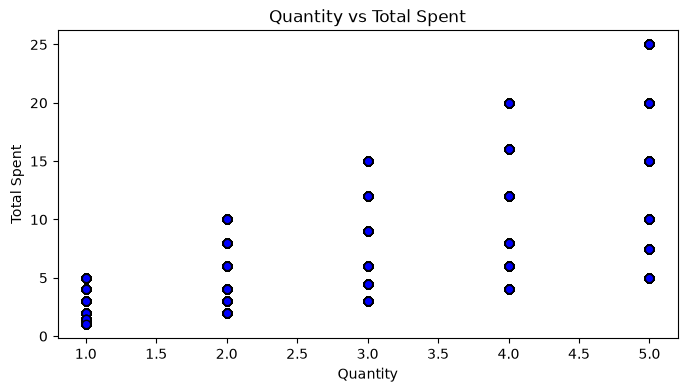

In [317]:
# Quantity vs Total Spent – Scatter Plot
plt.figure(figsize=(8,4))

plt.scatter(df["Quantity"], df["Total Spent"],
            color="blue", edgecolor="black")

plt.title("Quantity vs Total Spent")
plt.xlabel("Quantity")
plt.ylabel("Total Spent")
plt.show()

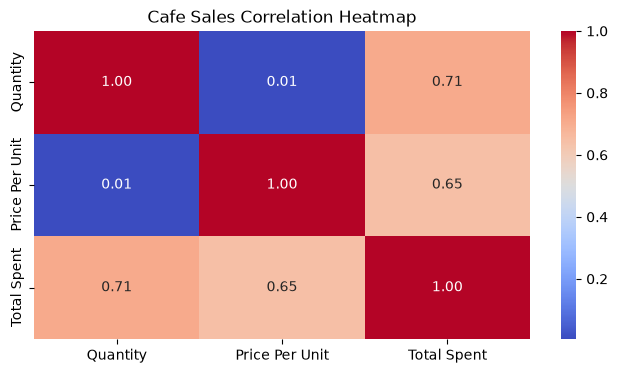

In [318]:
# Correlation – Heatmap
plt.figure(figsize=(8,4))

corr = df[["Quantity", "Price Per Unit", "Total Spent"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Cafe Sales Correlation Heatmap")
plt.show()

business insights

• Product Performance: Analyzed item-wise sales to identify high-performing and low-performing products. This helps the cafe understand which products need more attention.

• Sales Trends: Studied monthly sales patterns to understand changes in business performance and identify periods that may need additional promotions.

• Customer Preferences: Analyzed payment methods to understand customer payment preferences and improve payment convenience.

• Location Performance: Compared sales across different locations to identify better-performing locations and areas that may need improvement.

• Quantity and Revenue Analysis: Examined the relationship between product quantity and total sales to understand how order quantities contribute to cafe revenue.

conclusion and recommendations

• Data Analysis: Python helped analyze and understand cafe sales data.   

                       
• Sales Improvement: Focus on promoting popular products.


• Marketing Strategy: Provide special offers to attract more customers.


• Customer Satisfaction: Improve customer experience and service.


• Business Growth: Use sales insights to make better business decisions.